# Final Project: Model Deployment

**Junico - 2802518383**

Link video : https://youtu.be/q6yKuG8h3dQ 


## Setup & Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Class OOP buatan sendiri (dari file .py terpisah)
from data_cleaner import DataCleaner
from preprocessor import Preprocessor
from model_trainer import ModelTrainer

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 90
pd.set_option('display.max_columns', None)

# >>> SESUAIKAN PATH INI dengan lokasi CSV di komputer Anda <<<
DATA_PATH = 'data/data_A.csv'

## 1. Loading Data

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Jumlah baris: {df.shape[0]}, Jumlah kolom: {df.shape[1]}")
df.head()

Jumlah baris: 25000, Jumlah kolom: 29


,Unnamed: 0,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0,0xa658,CUS_0x936d,March,Alistair Barrs,8466,703-48-3482,_______,100433.58,8074.465000,1,5,10,2,"Student Loan, and Debt Consolidation Loan",13,4,12.59,3.0,Good,1023.93,33.471395,20 Years and 5 Months,No,100.163466,758.0704866746678,Low_spent_Medium_value_payments,229.21254743638283,Standard
1,1,0x6739,CUS_0x9a29,August,Phila,25,339-28-0072,Developer,33119.82,3024.985000,10,5,32,5,"Home Equity Loan, Mortgage Loan, Home Equity L...",50,18,15.79,10.0,Bad,2545.0,33.810567,14 Years and 8 Months,Yes,111.422702,NaN,Low_spent_Small_value_payments,370.6074980582689,Poor
2,2,0xdcf5,CUS_0x12a9,April,Driverb,44,583-20-9758,_______,44822.21,3555.184167,1,4,2,4,"Credit-Builder Loan, Debt Consolidation Loan, ...",14,8,4.03,0.0,Good,730.64,31.145739,23 Years and 10 Months,NM,135.044286,256.4742969677053,Low_spent_Medium_value_payments,243.99983412342044,Standard
3,3,0x14453,CUS_0x3bad,June,Prasadc,29,510-25-2095,Musician,142081.48,11771.123333,6,6,15,3_,"Personal Loan, Not Specified, and Mortgage Loan",29,20,8.21,4.0,Standard,932.32,28.409526,27 Years and 0 Months,No,180.616478,423.96126196668365,Low_spent_Small_value_payments,862.534593039876,Standard
4,4,0x1198e,CUS_0xa3e1,January,Poornimai,45,943-92-4350,Scientist,19267.27_,1374.605833,10,8,25,6,"Home Equity Loan, Auto Loan, Payday Loan, Not ...",33,NaN,19.7,6.0,Bad,3777.55,28.373426,10 Years and 3 Months,Yes,78.954825,133.56850235207634,Low_spent_Small_value_payments,214.93725572483646,Poor


In [3]:
# Tipe data tiap kolom — perhatikan banyak kolom numerik yang terbaca 'object' (string)
df.dtypes

Unnamed: 0                    int64
ID                           object
Customer_ID                  object
Month                        object
Name                         object
Age                          object
SSN                          object
Occupation                   object
Annual_Income                object
Monthly_Inhand_Salary       float64
Num_Bank_Accounts             int64
Num_Credit_Card               int64
Interest_Rate                 int64
Num_of_Loan                  object
Type_of_Loan                 object
Delay_from_due_date           int64
Num_of_Delayed_Payment       object
Changed_Credit_Limit         object
Num_Credit_Inquiries        float64
Credit_Mix                   object
Outstanding_Debt             object
Credit_Utilization_Ratio    float64
Credit_History_Age           object
Payment_of_Min_Amount        object
Total_EMI_per_month         float64
Amount_invested_monthly      object
Payment_Behaviour            object
Monthly_Balance             

## 2. Distribusi Target (`Credit_Score`)

Credit_Score
Standard    13330
Poor         7302
Good         4368
Name: count, dtype: int64

Proporsi:
Credit_Score
Standard    0.533
Poor        0.292
Good        0.175
Name: proportion, dtype: float64


C:\Users\User\AppData\Local\Temp\ipykernel_15548\2827944268.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=target_counts.index, y=target_counts.values, ax=ax, palette='viridis')


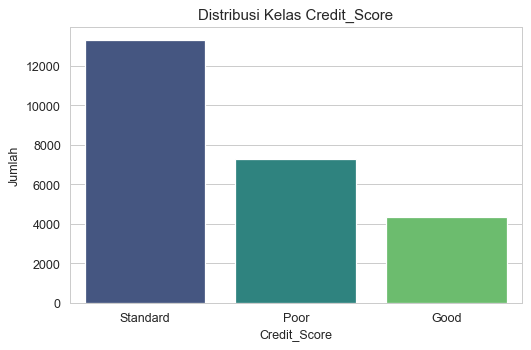

In [4]:
target_counts = df['Credit_Score'].value_counts()
print(target_counts)
print()
print("Proporsi:")
print(df['Credit_Score'].value_counts(normalize=True).round(3))

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=target_counts.index, y=target_counts.values, ax=ax, palette='viridis')
ax.set_title('Distribusi Kelas Credit_Score')
ax.set_ylabel('Jumlah')
plt.tight_layout()
plt.show()

**Observasi:** Kelas tidak seimbang — Standard (~53%) mendominasi, Good hanya ~17%.
Karena itu saya memakai **macro-F1** sebagai metrik utama (memperlakukan semua kelas sama penting),
bukan accuracy yang kurang cocok pada data imbalanced.

## 3. Analisis Kualitas Data

### 3.1 Kolom numerik tersimpan sebagai string dengan karakter aneh

In [7]:
# Contoh: Age, Annual_Income punya karakter '_' dan nilai mustahil
for col in ['Age', 'Annual_Income', 'Num_of_Loan']:
    sample = df[col].astype(str).head(8).tolist()
    print(f"{col}: {sample}")

Age: ['8466', '25', '44', '29', '45', '49', '18', '51']
Annual_Income: ['100433.58', '33119.82', '44822.21', '142081.48', '19267.27_', '177723.8', '53251.36', '61358.82']
Num_of_Loan: ['2', '5', '4', '3_', '6', '3', '3', '0']


### 3.2 Outlier ekstrem (data entry error)

In [6]:
# Konversi sementara semua ke numerik untuk melihat rentang nilai
def quick_numeric(s):
    return pd.to_numeric(s.astype(str).str.replace('_', '', regex=False), errors='coerce')

for col in ['Age', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate']:
    vals = quick_numeric(df[col])
    print(f"{col:25s} min={vals.min():>12.1f}  max={vals.max():>12.1f}  median={vals.median():.1f}")

Age                       min=      -500.0  max=      8698.0  median=33.0
Num_Bank_Accounts         min=        -1.0  max=      1798.0  median=6.0
Num_Credit_Card           min=         0.0  max=      1499.0  median=5.0
Interest_Rate             min=         1.0  max=      5775.0  median=13.0


**Observasi:** Terlihat nilai mustahil seperti `Age` hingga ribuan tahun, `Num_Bank_Accounts` ribuan.

### 3.3 Placeholder yang sebenarnya berarti 'missing'

In [5]:
placeholders = {
    'Occupation': '_______',
    'Credit_Mix': '_',
    'Payment_of_Min_Amount': 'NM',
    'Payment_Behaviour': '!@9#%8',
}
for col, ph in placeholders.items():
    n = (df[col] == ph).sum()
    print(f"{col:25s} berisi placeholder '{ph}' sebanyak {n} baris")

Occupation                berisi placeholder '_______' sebanyak 1770 baris
Credit_Mix                berisi placeholder '_' sebanyak 5066 baris
Payment_of_Min_Amount     berisi placeholder 'NM' sebanyak 3000 baris
Payment_Behaviour         berisi placeholder '!@9#%8' sebanyak 1852 baris


### 3.4 Missing values

C:\Users\User\AppData\Local\Temp\ipykernel_15548\3769988375.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing.values, y=missing.index, ax=ax, palette='rocket')


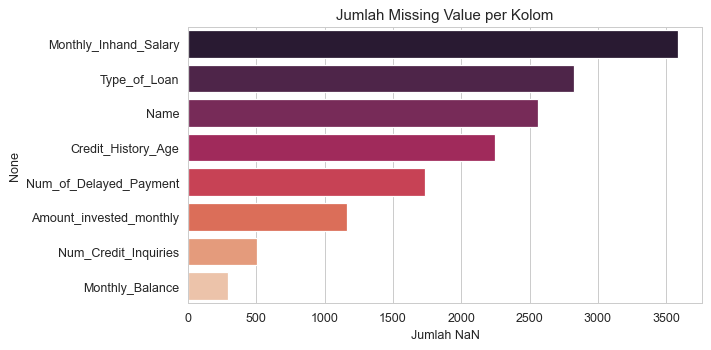

Monthly_Inhand_Salary      3583
Type_of_Loan               2828
Name                       2560
Credit_History_Age         2249
Num_of_Delayed_Payment     1733
Amount_invested_monthly    1164
Num_Credit_Inquiries        506
Monthly_Balance             289
dtype: int64

In [11]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=missing.values, y=missing.index, ax=ax, palette='rocket')
ax.set_title('Jumlah Missing Value per Kolom')
ax.set_xlabel('Jumlah NaN')
plt.tight_layout()
plt.show()
missing

## 4. Data Cleaning (class `DataCleaner`)

Semua masalah yang di dapatkan dari analisis kualitas data ditangani oleh class `DataCleaner` (custom sklearn transformer).
Langkah-langkahnya: strip karakter `_`, ubah placeholder & outlier mustahil jadi NaN,
parse `Credit_History_Age` ke bulan, multi-label encode `Type_of_Loan`,
dan buang kolom non-prediktif (ID, Name, SSN, dll).

In [9]:
cleaner = DataCleaner()
df_clean = cleaner.fit_transform(df)

print(f"Sebelum cleaning: {df.shape}")
print(f"Sesudah cleaning: {df_clean.shape}")
print()
print("Kolom baru hasil encoding Type_of_Loan:")
print([c for c in df_clean.columns if c.startswith('has_') or c == 'Num_Loan_Types'])
df_clean.head()

Sebelum cleaning: (25000, 29)
Sesudah cleaning: (25000, 32)

Kolom baru hasil encoding Type_of_Loan:
['has_Auto_Loan', 'has_Credit_Builder_Loan', 'has_Debt_Consolidation_Loan', 'has_Home_Equity_Loan', 'has_Mortgage_Loan', 'has_Not_Specified', 'has_Payday_Loan', 'has_Personal_Loan', 'has_Student_Loan', 'Num_Loan_Types']


,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score,has_Auto_Loan,has_Credit_Builder_Loan,has_Debt_Consolidation_Loan,has_Home_Equity_Loan,has_Mortgage_Loan,has_Not_Specified,has_Payday_Loan,has_Personal_Loan,has_Student_Loan,Num_Loan_Types
0,NaN,NaN,100433.58,8074.465000,1.0,5.0,10.0,2.0,13,4.0,12.59,3.0,Good,1023.93,33.471395,245.0,No,100.163466,758.070487,Low_spent_Medium_value_payments,229.212547,Standard,0,0,1,0,0,0,0,0,1,2
1,25.0,Developer,33119.82,3024.985000,10.0,5.0,32.0,5.0,50,18.0,15.79,10.0,Bad,2545.00,33.810567,176.0,Yes,111.422702,NaN,Low_spent_Small_value_payments,370.607498,Poor,0,0,1,1,1,1,0,0,0,5
2,44.0,NaN,44822.21,3555.184167,1.0,4.0,2.0,4.0,14,8.0,4.03,0.0,Good,730.64,31.145739,286.0,NaN,135.044286,256.474297,Low_spent_Medium_value_payments,243.999834,Standard,0,1,1,0,0,0,1,0,0,4
3,29.0,Musician,142081.48,11771.123333,6.0,6.0,15.0,3.0,29,20.0,8.21,4.0,Standard,932.32,28.409526,324.0,No,180.616478,423.961262,Low_spent_Small_value_payments,862.534593,Standard,0,0,0,0,1,1,0,1,0,3
4,45.0,Scientist,19267.27,1374.605833,10.0,8.0,25.0,6.0,33,NaN,19.70,6.0,Bad,3777.55,28.373426,123.0,Yes,78.954825,133.568502,Low_spent_Small_value_payments,214.937256,Poor,1,0,0,1,0,1,1,0,0,6


In [10]:
# Verifikasi: kolom numerik kini bertipe float dengan rentang wajar
df_clean[['Age', 'Annual_Income', 'Num_Bank_Accounts', 'Interest_Rate']].describe()

,Age,Annual_Income,Num_Bank_Accounts,Interest_Rate
count,24334.000000,24743.000000,24661.000000,24521.000000
mean,33.239788,50814.502044,5.376789,14.584519
std,10.811738,39756.112316,2.584743,8.750682
min,14.000000,7005.930000,0.000000,1.000000
25%,24.000000,19460.217500,3.000000,8.000000
50%,33.000000,37188.100000,6.000000,13.000000
75%,42.000000,71820.130000,7.000000,20.000000
max,95.000000,952323.000000,11.000000,34.000000


## 5. Eksplorasi Data Setelah Cleaning

### 5.1 Distribusi fitur numerik kunci

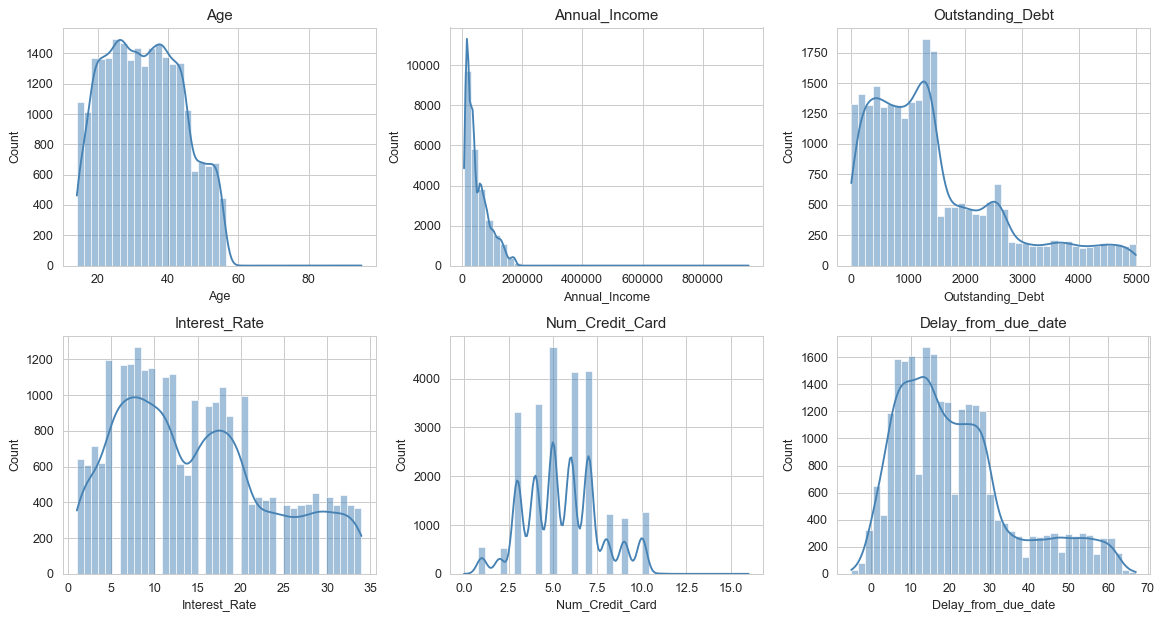

In [11]:
num_cols = ['Age', 'Annual_Income', 'Outstanding_Debt', 'Interest_Rate',
            'Num_Credit_Card', 'Delay_from_due_date']
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df_clean[col].dropna(), bins=40, ax=ax, kde=True, color='steelblue')
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Observasi:**  
`Age` = distribusi bimodal(2 puncak: ~25 dan ~40)   
`Annual_Income` = right-skewed ekstrem. Mayoritas dibawah 200k, tapi ada ekor panjang ke kanan (Wajar aja untuk data income)  
`Outstanding_Debt` = distribusi bimodal (~500 dan ~1200), menunjukkan ada dua kelompok nasabah yang punya utang kecil dan menengah  
`Interest_Rate` = multimodal (banyak puncak).   
`Num_Credit_Card` = diskrit dengan spike di angka bulat (2, 5, 7)  
`Delay_from_due_date` = right-skewed. Mayoritas nasabah keterlambatannya 0–20 hari, tapi ada yang sampai 60+ hari  

### 5.2 Hubungan fitur dengan target

C:\Users\User\AppData\Local\Temp\ipykernel_15548\2874947427.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Credit_Score', y=col, ax=ax,
C:\Users\User\AppData\Local\Temp\ipykernel_15548\2874947427.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Credit_Score', y=col, ax=ax,
C:\Users\User\AppData\Local\Temp\ipykernel_15548\2874947427.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Credit_Score', y=col, ax=ax,


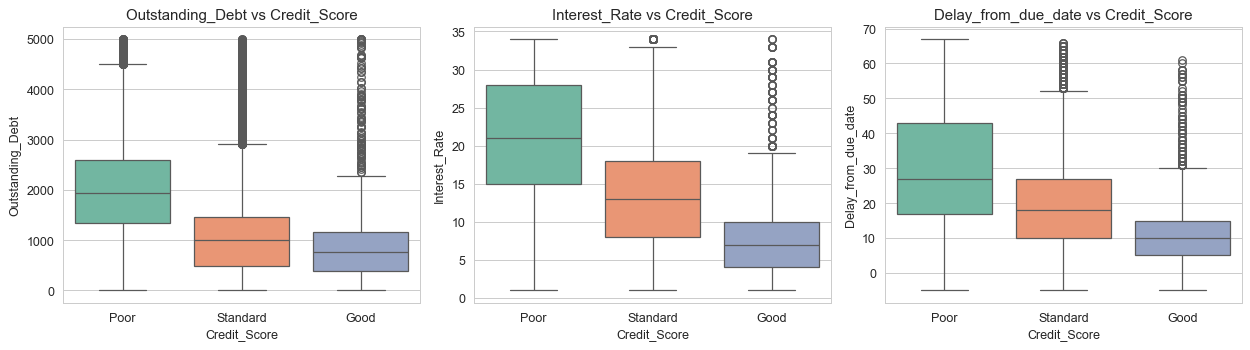

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ['Outstanding_Debt', 'Interest_Rate', 'Delay_from_due_date']):
    sns.boxplot(data=df_clean, x='Credit_Score', y=col, ax=ax,
                order=['Poor', 'Standard', 'Good'], palette='Set2')
    ax.set_title(f'{col} vs Credit_Score')
plt.tight_layout()
plt.show()

**Observasi:** Nasabah dengan `Credit_Score` = Poor cenderung punya outstanding debt,
suku bunga, dan keterlambatan pembayaran yang lebih tinggi — sesuai intuisi finansial.

### 5.3 Korelasi antar fitur numerik

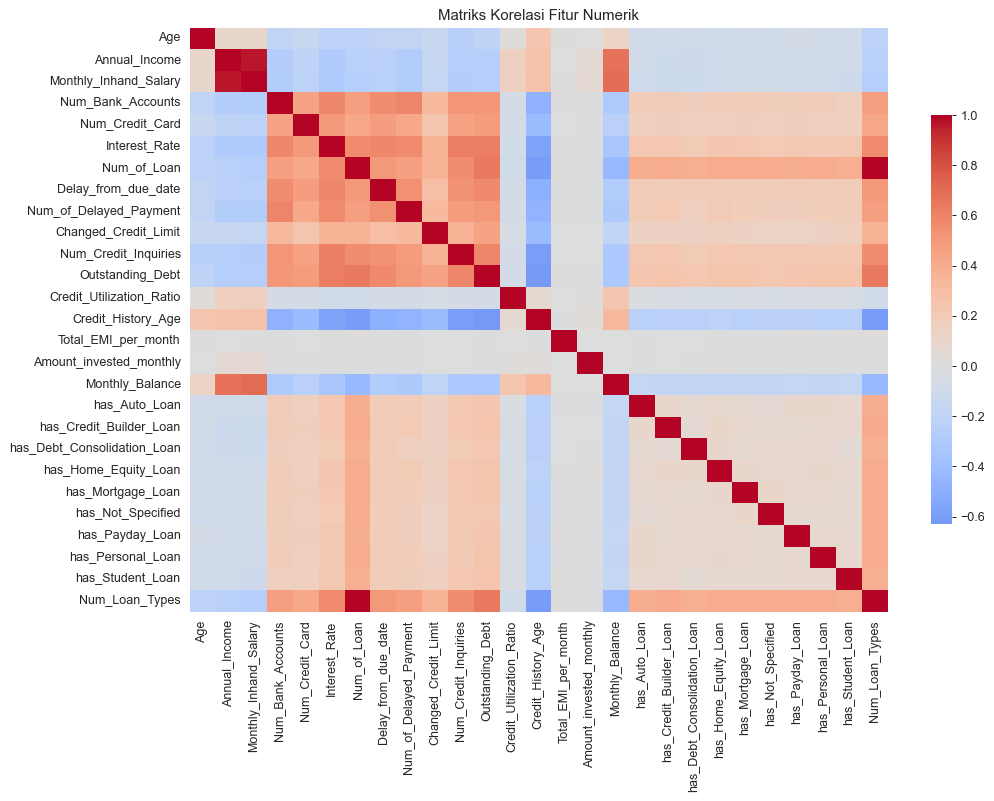

In [13]:
num_features = df_clean.select_dtypes(include=[np.number]).columns
corr = df_clean[num_features].corr()

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corr, cmap='coolwarm', center=0, ax=ax,
            cbar_kws={'shrink': 0.7}, square=False)
ax.set_title('Matriks Korelasi Fitur Numerik')
plt.tight_layout()
plt.show()

**Observasi:** Ditemukan multikolinearitas antara `Annual_Income` dan `Monthly_Inhand_Salary` lalu `Credit_History_Age` menunjukkan korelasi negatif dengan fitur resiko (delay, interest_rate)

## 6. Preprocessing & Train/Test Split

`Preprocessor` (class custom) menangani imputasi missing value, scaling numerik,
dan encoding kategorik (OneHot untuk nominal, Ordinal untuk `Credit_Mix`).
Target di-encode dengan `LabelEncoder`.

In [14]:
# Pisahkan fitur & target
X = df_clean.drop(columns=['Credit_Score'])
y_raw = df_clean['Credit_Score']

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)
print("Mapping target:", dict(zip(label_encoder.classes_, range(len(label_encoder.classes_)))))

# Split 80/20 stratified
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

# Fit preprocessor pada train, transform keduanya
preprocessor = Preprocessor()
X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)
print(f"Jumlah fitur setelah preprocessing: {X_train_p.shape[1]}")

Mapping target: {'Good': 0, 'Poor': 1, 'Standard': 2}
Train: (20000, 31), Test: (5000, 31)
Jumlah fitur setelah preprocessing: 51


## 7. Perbandingan Model

Empat model dibandingkan menggunakan **5-fold cross-validation** dengan metrik macro-F1.
Cross-validation dipakai (bukan single split) agar perbandingan lebih stabil dan tidak
bias terhadap satu split kebetulan.

In [15]:
trainer = ModelTrainer(random_state=42)
cv_results = trainer.compare_models(X_train_p, y_train)
cv_results[['model', 'cv_mean', 'cv_std']]

Membandingkan 4 model via 5-fold CV...
Scoring: f1_macro

  Training LogisticRegression... mean=0.5988 ± 0.0090
  Training RandomForest... mean=0.6966 ± 0.0046
  Training XGBoost... mean=0.6841 ± 0.0077
  Training LightGBM... mean=0.6843 ± 0.0039

>>> Model terbaik (default params): RandomForest
    CV f1_macro: 0.6966


,model,cv_mean,cv_std
0,RandomForest,0.696557,0.004580
1,LightGBM,0.684275,0.003852
2,XGBoost,0.684139,0.007699
3,LogisticRegression,0.598795,0.008971


C:\Users\User\AppData\Local\Temp\ipykernel_15548\3866591669.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cv_results, x='cv_mean', y='model', ax=ax,


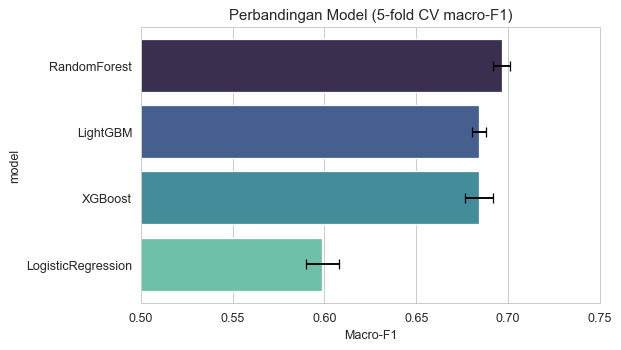

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=cv_results, x='cv_mean', y='model', ax=ax,
            palette='mako', xerr=None)
ax.errorbar(cv_results['cv_mean'], range(len(cv_results)),
            xerr=cv_results['cv_std'], fmt='none', c='black', capsize=4)
ax.set_title('Perbandingan Model (5-fold CV macro-F1)')
ax.set_xlabel('Macro-F1')
ax.set_xlim(0.5, 0.75)
plt.tight_layout()
plt.show()

**Interpretasi:** RandomForest unggul dengan CV macro-F1 0.6966, namun selisih dengan LightGBM dan XGBoost kurang dari 2% ini menunjukkan ketiga model gradient boosting dan ensemble memiliki kapabilitas serupa pada dataset ini. LogisticRegression tertinggal signifikan (~10%), mengonfirmasi bahwa pola dalam data bersifat non-linear. RandomForest dipilih untuk tahap tuning karena mean CV tertinggi, meski LightGBM menunjukkan variance lebih kecil.

## 8. Hyperparameter Tuning & Evaluasi Final

Model terbaik (RandomForest) di-tune dengan GridSearchCV. `max_depth` sengaja dibatasi
ke 10 untuk menghasilkan model ringan (~15 MB) yang mudah di-deploy — trade-off akurasi
vs ukuran model.

In [17]:
trainer.tune_best_model(X_train_p, y_train)


Tuning hyperparameter untuk RandomForest...
Total kombinasi: 4 × 5 folds = 20 fits

>>> Best params: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
    Best CV score: 0.6720
    CV score default (unconstrained): 0.6966
    Selisih: -0.0245
    (Negatif karena model dibatasi untuk deployment ringan — trade-off akurasi vs ukuran)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

In [18]:
# Evaluasi pada test set yang belum pernah dilihat
report = trainer.evaluate_on_test(X_test_p, y_test, label_names=label_encoder.classes_)


EVALUASI FINAL DI TEST SET
Macro-F1: 0.6925  |  Accuracy: 0.7190

Classification Report:
              precision    recall  f1-score   support

        Good       0.59      0.62      0.61       874
        Poor       0.75      0.68      0.71      1460
    Standard       0.74      0.77      0.76      2666

    accuracy                           0.72      5000
   macro avg       0.70      0.69      0.69      5000
weighted avg       0.72      0.72      0.72      5000



### 8.1 Confusion Matrix

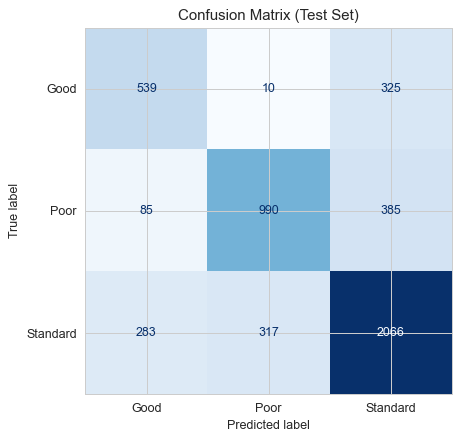

In [19]:
y_pred = trainer.tuned_model_.predict(X_test_p)
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(cm, display_labels=label_encoder.classes_)
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Confusion Matrix (Test Set)')
plt.tight_layout()
plt.show()

**Observasi:** Kelas Good (minoritas) paling sering tertukar dengan Standard,
karena jumlah sampelnya paling sedikit. Ini area yang bisa ditingkatkan dengan
teknik seperti SMOTE atau `class_weight='balanced'`.

## 9. Feature Importance

Fitur mana yang paling berpengaruh terhadap prediksi RandomForest.

C:\Users\User\AppData\Local\Temp\ipykernel_15548\1527470444.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=imp_df, x='importance', y='feature', ax=ax, palette='flare')


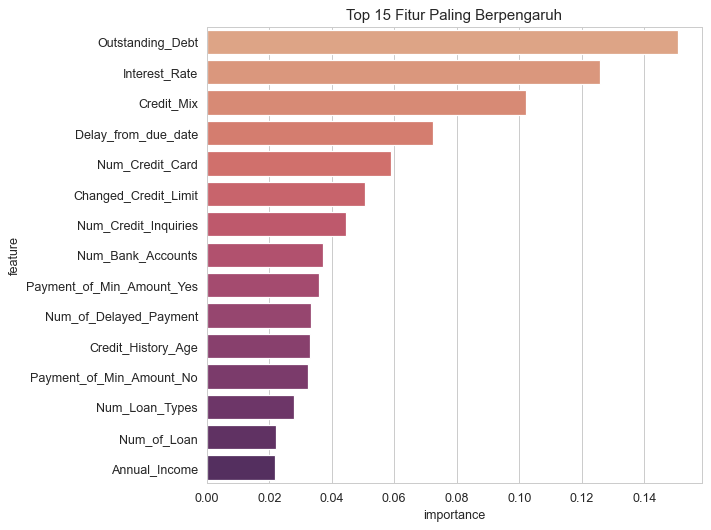

,feature,importance
11,Outstanding_Debt,0.150952
5,Interest_Rate,0.125907
41,Credit_Mix,0.102257
7,Delay_from_due_date,0.072429
4,Num_Credit_Card,0.058899
9,Changed_Credit_Limit,0.050705
10,Num_Credit_Inquiries,0.044558
3,Num_Bank_Accounts,0.037207
34,Payment_of_Min_Amount_Yes,0.035770
8,Num_of_Delayed_Payment,0.033425


In [20]:
importances = trainer.tuned_model_.feature_importances_
feat_names = preprocessor.get_feature_names_out()

imp_df = (pd.DataFrame({'feature': feat_names, 'importance': importances})
          .sort_values('importance', ascending=False)
          .head(15))

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=imp_df, x='importance', y='feature', ax=ax, palette='flare')
ax.set_title('Top 15 Fitur Paling Berpengaruh')
plt.tight_layout()
plt.show()
imp_df

## 10. Kesimpulan

**Eksperimen yang dilakukan:**
1. **4 baseline model** dibandingkan (Logistic Regression, Random Forest, XGBoost, LightGBM)
2. **Hyperparameter tuning** Random Forest dengan GridSearchCV (5-fold, f1_macro)
3. **Evaluasi multiclass** pakai macro-averaged Accuracy, Precision, Recall, F1

**Model terbaik:** Random Forest (Tuned) — CV macro-F1 tertinggi (0.6966 → 0.6925 setelah tuning dengan max_depth=10).

**Feature importance** menunjukkan `Outstanding_Debt`, `Interest_Rate`, `Credit_Mix`,
dan `Delay_from_due_date` paling berpengaruh 